# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/flyrank-bih/flyrank-ml-internship-starter/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

**Queue:** all 21,758 pages of the review population, ranked by the Logistic Regression score from ML-08. Every page is scored by a model that never saw its client (5-fold split grouped by `client_id`).

**Reason code:** the feature family that pushes a page's score up the most relative to the average page. The model is linear, so each feature's push is exact: its coefficient times how far the page is from the average. The six families are visibility consistency, volume, position and CTR, on-page engagement, page profile, and keyword and source. A reason code describes what the model is reacting to; it does not say what caused a page's change.

**Archetype → action:** each reason code maps to a human-review action. Every action is a review; none changes a page by itself.

| Reason code | The model is reacting to | Suggested human-review action |
|---|---|---|
| `visibility_gaps` | Few days with impressions in 90 days | Check for lost visibility, then refresh review |
| `weak_position_or_ctr` | Average position or CTR | Snippet and relevance review (title, description, intent) |
| `page_age_or_length` | Page age, update date or length | Refresh or expand review |
| `weak_engagement` | Engagement or scroll rate | On-page engagement review |
| `keyword_or_source` | Keyword demand, competition or the writing workflow | Check keyword demand and workflow; monitor (low actionability) |
| `volume_pattern` | Impressions, clicks or sessions totals | Monitor |

**Confidence label:** `higher` if the page has at least 500 impressions in 90 days, otherwise `lower`. It reflects how much evidence exists, not the chance that an action pays off.

**Protect check:** pages on page one (average position 1 to 10) that are at least 180 days old are flagged, because the evidence below shows such pages decay less often than average.

**Not used as reason codes:** the program's rule-style tags. They are checked in a separate cell because their link to decay turned out weak.

In [10]:
!test -d repo || git clone --depth 1 https://github.com/flyrank-bih/flyrank-ml-internship-starter.git repo
!cp -r repo/data .

In [11]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
df = df[df["trend_pct"].notna()].reset_index(drop=True)
df["is_decayed"] = ((df["trend_direction"] == "down") & (df["trend_pct"] <= -30)).astype(int)
df = df[df["impressions_90d"] >= 100].reset_index(drop=True)      # review population, as in ML-08

FORBIDDEN = ["trend_direction", "trend_pct", "is_decayed"] + \
            [c for c in df.columns if c.endswith(("_last_30d", "_prev_30d"))]
FEATURES = [c for c in df.columns if c not in FORBIDDEN + ["content_id", "client_id"]]

X_lr = df[FEATURES].copy()
y = df["is_decayed"].values
groups = df["client_id"].values
NUMERIC = X_lr.select_dtypes(include="number").columns.tolist()
CATEGORICAL = [c for c in FEATURES if c not in NUMERIC]
for c in CATEGORICAL:
    X_lr[c] = X_lr[c].astype(object)

def make_logistic():
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000, random_state=SEED))])

print("Review population:", f"{len(df):,}", "pages |", len(set(groups)), "clients | base rate:", round(y.mean(), 3))
print("Features:", len(FEATURES), "| sklearn", sklearn.__version__, "| seed", SEED)

Review population: 21,758 pages | 30 clients | base rate: 0.514
Features: 34 | sklearn 1.6.1 | seed 42


In [12]:
FAMILIES = {
    "visibility consistency": ["days_with_impressions", "days_with_sessions"],
    "volume": ["impressions_90d", "clicks_90d", "pageviews_90d", "sessions_90d", "users_90d",
               "engaged_sessions_90d", "ai_sessions_90d", "scroll_events_90d", "impression_tier"],
    "position and CTR": ["avg_position", "ctr", "position_tier"],
    "on-page engagement": ["engagement_rate", "scroll_rate", "ai_traffic_pct"],
    "page profile": ["word_count", "char_count", "content_age_days", "days_since_last_update", "age_tier",
                     "age_tier_order", "freshness_tier", "word_count_tier", "char_count_tier",
                     "content_type", "main_intent"],
    "keyword and source": ["search_volume", "competition", "competition_level", "cpc",
                           "provider_used", "model_used"],
}
FAMILY_CODE = {   # family -> (reason code, suggested human-review action)
    "visibility consistency": ("visibility_gaps",      "Check for lost visibility, then refresh review"),
    "position and CTR":       ("weak_position_or_ctr", "Snippet and relevance review (title, description, intent)"),
    "page profile":           ("page_age_or_length",   "Refresh or expand review"),
    "on-page engagement":     ("weak_engagement",      "On-page engagement review"),
    "keyword and source":     ("keyword_or_source",    "Check keyword demand and workflow; monitor (low actionability)"),
    "volume":                 ("volume_pattern",       "Monitor"),
}
col_family = {c: f for f, cols in FAMILIES.items() for c in cols}
assert set(FEATURES) == set(col_family), "every feature needs exactly one family"

folds = list(GroupKFold(n_splits=5).split(df, y, groups))
score = np.zeros(len(y))
effect = pd.DataFrame(0.0, index=range(len(y)), columns=list(FAMILIES))
to_dense = lambda m: m.toarray() if hasattr(m, "toarray") else m
for tr, te in folds:
    model = make_logistic().fit(X_lr.iloc[tr], y[tr])
    score[te] = model.predict_proba(X_lr.iloc[te])[:, 1]
    prep, clf = model.named_steps["prep"], model.named_steps["model"]
    Xtr, Xte = to_dense(prep.transform(X_lr.iloc[tr])), to_dense(prep.transform(X_lr.iloc[te]))
    push = (Xte - Xtr.mean(axis=0)) * clf.coef_[0]          # push on the score relative to the average page
    for j, name in enumerate(prep.get_feature_names_out()):
        part = name.split("__", 1)[1]
        source = max((c for c in FEATURES if part == c or part.startswith(c + "_")), key=len)
        effect.loc[te, col_family[source]] += push[:, j]

driver = effect.idxmax(axis=1)
queue = df[["content_id", "impressions_90d", "days_with_impressions", "avg_position", "ctr", "word_count"]].copy()
queue["score"] = score
queue["reason_code"] = driver.map(lambda f: FAMILY_CODE[f][0])
queue["action"] = driver.map(lambda f: FAMILY_CODE[f][1])
queue["confidence"] = np.where(queue["impressions_90d"] >= 500, "higher", "lower")
queue["protect_check"] = (df["avg_position"] > 0) & (df["avg_position"] <= 10) & (df["content_age_days"] >= 180)
queue["decayed"] = df["is_decayed"].values                  # evaluation only, never exported
queue = queue.sort_values(["score", "content_id"], ascending=[False, True]).reset_index(drop=True)
queue.insert(0, "rank", queue.index + 1)

print("Queue built:", f"{len(queue):,}", "pages | base rate:", round(y.mean(), 3))
print("\nTop 500: primary reason code")
print(queue.head(500)["reason_code"].value_counts().to_string())
print("\nTop 500 by confidence:", queue.head(500)["confidence"].value_counts().to_dict())
print("Top 500 flagged for a protect check:", int(queue.head(500)["protect_check"].sum()))
print("\nFirst 10 rows:")
print(queue[["rank", "reason_code", "confidence", "impressions_90d", "days_with_impressions",
             "avg_position", "score"]].head(10).round(3).to_string(index=False))
print("\nDecay rate by reason code within the top 2,000 (observed; the label is used for evaluation only):")
print(queue.head(2000).groupby("reason_code")["decayed"].agg(pages="size", decay_rate="mean").round(3).to_string())

Queue built: 21,758 pages | base rate: 0.514

Top 500: primary reason code
reason_code
visibility_gaps         204
page_age_or_length      123
weak_position_or_ctr     81
keyword_or_source        69
weak_engagement          20
volume_pattern            3

Top 500 by confidence: {'lower': 308, 'higher': 192}
Top 500 flagged for a protect check: 107

First 10 rows:
 rank          reason_code confidence  impressions_90d  days_with_impressions  avg_position  score
    1       volume_pattern     higher             4238                     75           7.9  1.000
    2      visibility_gaps      lower              108                     36           2.1  0.982
    3 weak_position_or_ctr      lower              158                     50           2.6  0.972
    4      visibility_gaps      lower              354                     33           0.5  0.971
    5 weak_position_or_ctr      lower              331                     67           2.4  0.970
    6      visibility_gaps      lower   

In [13]:
imp, pos = df["impressions_90d"], df["avg_position"]
RULE_TAGS = {   # the guide's baseline tags that use only observable fields (declining_with_demand uses the label, so it is left out)
    "stale_visible_page":          (df["days_since_last_update"] >= 180) & (imp >= 500),
    "thin_visible_page":           (df["word_count"] > 0) & (df["word_count"] < 1200) & (imp >= 250),
    "page_one_decay_risk":         (pos > 0) & (pos <= 10) & (df["content_age_days"] >= 180),
    "low_ctr_visible_page":        (imp >= 500) & (pos > 0) & (pos <= 20) & (df["ctr"] < 0.5),
    "low_engagement_visible_page": (df["sessions_90d"] >= 30) & ((df["engagement_rate"] < 30) | (df["scroll_rate"] < 30)),
    "neglected_low_volume (ML-07)": imp.between(100, 499) & (df["days_since_last_update"] >= 91),
}
rows = []
for tag, mask in RULE_TAGS.items():
    m = mask.values
    rows.append({"tag": tag, "pages": int(m.sum()), "share of pages": f"{m.mean():.1%}",
                 "decay rate": round(y[m].mean(), 3), "lift": round(y[m].mean() / y.mean(), 2)})
print(f"Base rate: {y.mean():.3f}\n")
print(pd.DataFrame(rows).to_string(index=False))

Base rate: 0.514

                         tag  pages share of pages  decay rate  lift
          stale_visible_page     17           0.1%       0.824  1.60
           thin_visible_page     80           0.4%       0.512  1.00
         page_one_decay_risk   4898          22.5%       0.458  0.89
        low_ctr_visible_page   9673          44.5%       0.527  1.03
 low_engagement_visible_page   7058          32.4%       0.431  0.84
neglected_low_volume (ML-07)   1531           7.0%       0.591  1.15


**Observed**

**The queue.** 21,758 pages ranked by the Logistic Regression score, each scored by a model that never saw its client. In the top 500, the primary reason codes are `visibility_gaps` (204), `page_age_or_length` (123), `weak_position_or_ctr` (81), `keyword_or_source` (69), `weak_engagement` (20) and `volume_pattern` (3). Of the top 500, 192 pages have at least 500 impressions (confidence `higher`) and 308 have fewer (`lower`), and 107 are also flagged for a protect check.

**Evidence by reason code.** Within the top 2,000 pages, the observed decay rate is above the 0.514 base rate for every reason code with enough pages: `weak_position_or_ctr` 0.876 (178 pages), `visibility_gaps` 0.774 (629), `keyword_or_source` 0.714 (412), `weak_engagement` 0.691 (55) and `page_age_or_length` 0.642 (723). `volume_pattern` has only 3 pages, too few to read. The differences between codes are not tested for significance, so they are not ranked here.

**The program's rule-style tags are weak or reversed in this data** (independent checks, base rate 0.514):

| Tag | Pages | Decay rate | Lift |
|---|---|---|---|
| `page_one_decay_risk` | 4,898 | 0.458 | 0.89 |
| `low_engagement_visible_page` | 7,058 | 0.431 | 0.84 |
| `low_ctr_visible_page` | 9,673 | 0.527 | 1.03 |
| `thin_visible_page` | 80 | 0.512 | 1.00 |
| `neglected_low_volume` (my ML-07 rule) | 1,531 | 0.591 | 1.15 |
| `stale_visible_page` | 17 | 0.824 | 1.60 (too few pages to read) |

**The decay/refresh insight (directional).** In this snapshot:
- Pages most likely to be labeled decaying are those whose visibility has become patchy (fewer days with impressions), not pages that are simply old. Age and staleness alone were a weak signal (ML-07 verdict: mixed).
- Older page-one pages decayed *less* often than average (0.458 vs 0.514). That is why the queue carries a protect check instead of a default refresh for them.
- The paper reports a related pattern in a different data set: optimization flags mark leverage, not failure (its Myth #3). My tags are defined differently, so I treat the similarity as consistent with its caution, not as a replication.
- Part of the visibility-gap signal comes from the 90-day totals overlapping the label windows (section 3 of ML-09), so this insight describes pages whose recent activity is already weak. It does not forecast future decay or show that a refresh would help.

## 2. Intended use and limits

**Intended use.** A review queue for FlyRank editors and SEO staff. It suggests which pages to look at first when deciding on a content refresh, expansion, snippet fix or no action. It is a decision-support aid built from one snapshot (21,758 pages, 30 clients); it is not a production system.

**What the queue is.** A ranking of pages by how likely a model thinks they are to be labeled decaying (a drop of 30% or more in impressions, last 30 days vs prior 30 days), with a reason code that says what the model is reacting to.

**What it is not.**
- It does not say that a page needs a refresh, or that a refresh would help. "Decaying" here is an observed change in impressions, and I have no evidence about what a refresh does (the data has no before-and-after of an intervention).
- It does not forecast future decay. The label describes the current window, and the 90-day numbers the model uses overlap that window (ML-09, section 3).
- It is not a client-level or portfolio-level quality score.

**Limits that matter for use** (from ML-08 and ML-09):
- Lift@500 is 1.55x for this queue, with a 95% interval of 1.22 to 1.86 from resampling the 30 clients. Precision depends on the population rule (0.71 to 0.92 across two rules for Gradient boosting).
- 82% of the false positives in the top 500 had not fallen at all (grew or stayed stable), and 40% of decayed pages sat in the bottom half of the ranking.
- Without the 90-day activity numbers, the models' skill was weak (AUC 0.565 to 0.592).
- Decay rates differ a lot between clients (0.00 to 1.00), so results for a new client may differ.

**Cost and value.** Review time is the cost; the benefit is finding pages that are labeled decaying faster than by chance. I also measure the value at stake with click-equivalent value (clicks × CPC), the proxy the paper recommends in Finding #9 instead of impressions × CPC. It is a proxy, not revenue. The review time per page is an assumption that should be replaced with the team's real figure.

In [14]:
MINUTES_PER_REVIEW = 15          # assumption: replace with the team's real figure
K = 500
base = y.mean()

value_by_page = df.set_index("content_id")["clicks_90d"] * df.set_index("content_id")["cpc"].fillna(0)
queue["click_value"] = queue["content_id"].map(value_by_page)
total_value = queue["click_value"].sum()

def describe(name, picked):
    p = picked["decayed"].mean()
    return {"500-page review list": name, "decay rate": round(p, 3), "lift": round(p / base, 2),
            "reviews per decayed page": round(1 / p, 2),
            "share of click value": f"{picked['click_value'].sum() / total_value:.1%}",
            "median impressions": int(picked["impressions_90d"].median())}

random_row = {"500-page review list": "Random pages (expected)", "decay rate": round(base, 3), "lift": 1.00,
              "reviews per decayed page": round(1 / base, 2),
              "share of click value": f"{K / len(queue):.1%}",
              "median impressions": int(queue["impressions_90d"].median())}
lists = [describe("Model score (this queue)", queue.head(K)),
         describe("Value first (clicks x CPC)", queue.sort_values(["click_value", "content_id"], ascending=[False, True]).head(K)),
         random_row]
print(f"Base rate: {base:.3f} | assumed {MINUTES_PER_REVIEW} minutes per review\n")
print(pd.DataFrame(lists).to_string(index=False))

hours = K * MINUTES_PER_REVIEW / 60
extra = K * (queue.head(K)["decayed"].mean() - base)
print(f"\nReviewing {K} pages takes about {hours:.0f} hours at {MINUTES_PER_REVIEW} minutes each.")
print(f"Compared with random picks, the model-score list contains about {extra:.0f} more pages that were labeled decaying.")
print(f"CPC missing for {df['cpc'].isna().mean():.1%} of pages (counted as 0 value).")

Base rate: 0.514 | assumed 15 minutes per review

      500-page review list  decay rate  lift  reviews per decayed page share of click value  median impressions
  Model score (this queue)       0.796  1.55                      1.26                 0.4%                 360
Value first (clicks x CPC)       0.380  0.74                      2.63                86.2%               12389
   Random pages (expected)       0.514  1.00                      1.95                 2.3%                1728

Reviewing 500 pages takes about 125 hours at 15 minutes each.
Compared with random picks, the model-score list contains about 141 more pages that were labeled decaying.
CPC missing for 2.6% of pages (counted as 0 value).


**Observed** (500-page review lists, base rate 0.514, 15 minutes per review assumed):

| 500-page review list | Decay rate | Lift | Reviews per decayed page | Share of click value | Median impressions |
|---|---|---|---|---|---|
| Model score (this queue) | 0.796 | 1.55x | 1.26 | 0.4% | 360 |
| Value first (clicks × CPC) | 0.380 | 0.74x | 2.63 | 86.2% | 12,389 |
| Random pages (expected) | 0.514 | 1.00x | 1.95 | 2.3% | 1,728 |

- **Review efficiency.** Reviewing the 500 top-scored pages takes about 125 hours at the assumed 15 minutes each, and the list contains about 141 more pages labeled decaying than 500 random pages would. It takes 1.26 reviews per decaying page, against 1.95 at random.
- **Value at stake.** The model-score list holds only 0.4% of the portfolio's click-equivalent value; its median page has 360 impressions, against 1,728 across all pages. The queue finds likely decay on small pages.
- **The two goals pull apart.** The value-first list holds 86.2% of the click value but only 38.0% of its pages are labeled decaying, below chance (0.74x). In this snapshot, the pages with the most value at stake were less often labeled decaying.
- **What this means for use.** The queue is a screening list for likelihood, not a ranking of what is worth the most. A reviewer should check value (clicks and CPC) before spending time on any page, and the queue should not be used to claim that value will be recovered. A combined list that sorts the model's top pages by value was not tested here.
- **Assumptions.** 15 minutes per review is an assumption to replace with the team's figure. Click-equivalent value is a proxy; CPC is missing for 2.6% of pages and counted as zero value. "Labeled decaying" is an observed fall in impressions, not evidence that a refresh would pay off.

## 3. Human review + the no-go list

### Human-review rules (for every page in the queue)

A person reviews each page before anything is done to it. The reviewer works through these checks in order:

1. **Confirm the decline is real.** Look at the page's impressions over time in Search Console, not only the 30-day ratio. Rule out seasonality, tracking or indexing problems, and a one-off spike in the earlier window. In my review of the top pages, a notable share had not declined at all (see the count below).
2. **Check the evidence behind the score.** Pages with the `lower` confidence label (under 500 impressions) need extra evidence before any action, because a 30% change on a few hundred impressions can be noise.
3. **Check the value.** Look at clicks and CPC (the click-equivalent value). The queue ranks likelihood, not value, so a page with little value at stake may not be worth the time.
4. **Read the page.** The reason code points to where to look first; it is not a diagnosis. Decide whether the suggested action fits the page.
5. **Respect the protect check.** For pages flagged as page one and at least 180 days old, start from "leave it alone" and act only if you find a specific problem. Such pages decayed less often than average in this data.
6. **Record the decision.** Note what you did (refresh, expand, snippet fix, engagement fix, monitor or skip) and whether you agreed with the queue. These notes feed the monitoring triggers in section 4.

### The no-go list: what should not be automated

- **Publishing or rewriting content directly from the queue.** The queue is not evidence that a page needs changing, and this data has no before-and-after of any intervention.
- **Pruning, deleting, merging or redirecting pages.** These are hard to undo, and no part of this work tested them. `keyword_or_source` and `volume_pattern` are monitor-only actions.
- **Promising results.** No client-facing statement such as "this refresh will recover impressions". The evidence is observational.
- **Acting on pages the queue did not score.** Pages with no prior-period baseline (new or flat) or with under 100 impressions are outside the review population.
- **Comparing or ranking clients, writers or writing workflows with the queue.** Decay rates differ widely by client, the top pages come from a small number of clients, and the `keyword_or_source` code may stand in for client or workflow patterns.
- **Treating a reason code as a cause.** It describes what the model reacts to.
- **Using the queue for a new client without checking it first.** Results were tested on clients the model had not seen, but the spread between clients was wide.
- **Using the queue as proof that refreshing works.** Whether a refresh helps would need a designed comparison.

In [15]:
raw = pd.read_csv("data/raw/content_refresh_anonymized.csv")
no_baseline = int(raw["trend_pct"].isna().sum())
labeled_pages = len(raw) - no_baseline
small = labeled_pages - len(queue)
print(f"Pages not scored: {no_baseline:,} with no prior-period baseline and {small:,} with fewer than 100 impressions "
      f"({no_baseline + small:,} of {len(raw):,})")

top = queue.head(500)
client_of = df.set_index("content_id")["client_id"]
share = top["content_id"].map(client_of).value_counts(normalize=True)
print(f"\nIn the top 500:")
print(f"  lower-confidence pages (under 500 impressions): {(top['confidence'] == 'lower').sum()}")
print(f"  protect-check pages (page one, 180+ days old):  {int(top['protect_check'].sum())}")
print(f"  monitor-only or low-actionability actions:       {int(top['action'].str.contains('Monitor|monitor').sum())}")
print(f"  pages that did not decay (acting on them would be wrong): {(top['decayed'] == 0).sum()} ({(top['decayed'] == 0).mean():.0%})")
print(f"  clients represented: {len(share)}; largest client's share: {share.iloc[0]:.0%}")

Pages not scored: 3,388 with no prior-period baseline and 4,854 with fewer than 100 impressions (8,242 of 30,000)

In the top 500:
  lower-confidence pages (under 500 impressions): 308
  protect-check pages (page one, 180+ days old):  107
  monitor-only or low-actionability actions:       72
  pages that did not decay (acting on them would be wrong): 102 (20%)
  clients represented: 22; largest client's share: 25%


**Observed** (from the queue, base rate 0.514):

- **Pages the queue does not score:** 8,242 of 30,000 (3,388 with no prior-period baseline and 4,854 with fewer than 100 impressions). Acting on them would be outside the validated population.
- **Evidence behind the top pages:** of the top 500, 308 (62%) have the `lower` confidence label (under 500 impressions), so the second review rule applies to most of the queue.
- **Protect check:** 107 of the top 500 are page-one pages at least 180 days old, so about one in five top pages starts from "leave it alone".
- **Low-actionability actions:** 72 of the top 500 carry a monitor-only action (`keyword_or_source` or `volume_pattern`).
- **Automating would misfire:** 102 of the top 500 (20%) did not decay, so roughly one in five automated actions would be applied to a page whose impressions had not fallen by 30%.
- **Client concentration:** the top 500 come from 22 clients, and the largest client holds 25% of them, which is why the queue should not be used to compare clients.

## 4. Monitoring / retrain triggers

Light, practical triggers for a small team, not a production monitoring system. Each trigger has a reference value measured in this snapshot and a starting threshold. The thresholds are starting points, not tuned values, and should be revisited after the first few review batches.

**Schedule.** Re-score the pages monthly. Re-audit and retrain when any trigger below fires, and at least once a quarter.

In [16]:
# Reference values from this snapshot
top = queue.head(500)
model_p500 = top["decayed"].mean()
false_share = 1 - model_p500

baseline_score = np.where(
    (df["impressions_90d"] >= 100) & (df["impressions_90d"] < 500) & (df["days_since_last_update"] >= 91),
    df["days_since_last_update"].clip(upper=365) / 365 * (500 - df["impressions_90d"]) / 400, 0.0)
order = np.lexsort((df["content_id"].values, -baseline_score))
rule_p500 = y[order[:500]].mean()

fold_rates = [y[te].mean() for _, te in folds]
largest_client_share = pd.Series(groups).value_counts(normalize=True).iloc[0]

triggers = pd.DataFrame([
    {"trigger": "1. Hit rate",
     "watch": "Share of reviewed top-ranked pages that the reviewer confirms as genuinely declining",
     "reference": f"queue {model_p500:.3f} vs Week-4 rule {rule_p500:.3f} (top 500)",
     "starting threshold": f"below {rule_p500:.2f} in two batches in a row: stop using the queue and re-audit"},
    {"trigger": "2. Base-rate drift",
     "watch": "Share of pages labeled decaying in a new batch",
     "reference": f"overall {y.mean():.3f}; client-grouped folds ranged {min(fold_rates):.3f} to {max(fold_rates):.3f}",
     "starting threshold": f"outside {min(fold_rates):.2f} to {max(fold_rates):.2f}: check the data before trusting scores"},
    {"trigger": "3. Reviewer disagreement",
     "watch": "Share of top-ranked pages the reviewer rejects",
     "reference": f"{false_share:.0%} of the top 500 did not decay",
     "starting threshold": f"above {2 * false_share:.0%}: re-audit"},
    {"trigger": "4. New client or client mix",
     "watch": "A client added, or one client's share of pages changing",
     "reference": f"largest client holds {largest_client_share:.1%} of pages",
     "starting threshold": "any new client, or a share above the current largest: check on that client before use"},
    {"trigger": "5. Data or definition change",
     "watch": "Changes to the 30-day windows, the trend definition, impression sources or columns",
     "reference": "leakage audit passed on the current definition",
     "starting threshold": "any change: re-run the leakage audit before scoring"},
])
pd.set_option("display.max_colwidth", None)
print(triggers.to_string(index=False))

                     trigger                                                                                watch                                                 reference                                                                    starting threshold
                 1. Hit rate Share of reviewed top-ranked pages that the reviewer confirms as genuinely declining                queue 0.796 vs Week-4 rule 0.618 (top 500)                 below 0.62 in two batches in a row: stop using the queue and re-audit
          2. Base-rate drift                                       Share of pages labeled decaying in a new batch overall 0.514; client-grouped folds ranged 0.379 to 0.717                           outside 0.38 to 0.72: check the data before trusting scores
    3. Reviewer disagreement                                       Share of top-ranked pages the reviewer rejects                          20% of the top 500 did not decay                                                       

**Observed** (reference values measured on this snapshot):

| Trigger | Watch | Reference value | Starting threshold |
|---|---|---|---|
| 1. Hit rate | Share of reviewed top-ranked pages that a reviewer confirms as declining | Queue 0.796 vs Week-4 rule 0.618 (top 500) | Below 0.62 in two batches in a row: stop using the queue and re-audit |
| 2. Base-rate drift | Share of pages labeled decaying in a new batch | Overall 0.514; client-grouped folds ranged 0.379 to 0.717 | Outside 0.38 to 0.72: check the data before trusting scores |
| 3. Reviewer disagreement | Share of top-ranked pages the reviewer rejects | 20% of the top 500 did not decay | Above 41%: re-audit |
| 4. New client or client mix | A client added, or one client's share of pages changing | Largest client holds 30.2% of pages | Any new client, or a share above the current largest: check before use |
| 5. Data or definition change | Changes to the 30-day windows, trend definition, impression sources or columns | Leakage audit passed on the current definition | Any change: re-run the leakage audit before scoring |

- **The thresholds are starting points, not tuned values.** Trigger 3 is set at twice the share observed here and trigger 2 at the fold range, both by rule of thumb. They should be revisited after the first few review batches.
- **Trigger 1 needs follow-up from reviewers.** The "hit rate" only exists if reviewers record whether each reviewed page was really declining (review rule 6 in section 3). Without those notes the trigger cannot fire.
- **The reference values come from one snapshot** of 21,758 pages and 30 clients, and the fold range is wide partly because one client sits alone in a fold. A shift in these numbers is a prompt to look, not proof that the queue has failed.
- **Schedule:** re-score monthly, re-audit when a trigger fires, and in any case once a quarter.

## 5. Exports for the paper

Three kinds of files, written by this notebook into `work/outputs/` and `work/figures/`:

| File | Purpose | In git? |
|---|---|---|
| `work/outputs/action_queue.csv` | The ranked queue: rank, page id, score, reason code, action, confidence, protect check, a few observed page fields, and click value | **No** (data files stay out of git; the notebook regenerates it) |
| `work/outputs/playbook_summary.json` | The numbers the paper will quote, as a small receipt (no ids, no data) | Yes |
| `work/figures/queue_precision_by_k.png` and `work/figures/decay_rate_by_reason_code.png` | Two figures for the recommendations section | Yes |

The exported queue does not contain the decay label or any 30-day window column; the cell checks the header of the file it just wrote.

In [17]:
import json, os
import matplotlib.pyplot as plt

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# 1) The ranked queue (stays out of git). The label column is NOT exported.
export_cols = ["rank", "content_id", "score", "reason_code", "action", "confidence", "protect_check",
               "impressions_90d", "days_with_impressions", "avg_position", "ctr", "click_value"]
queue[export_cols].round({"score": 4, "click_value": 2}).to_csv("work/outputs/action_queue.csv", index=False)

written = list(pd.read_csv("work/outputs/action_queue.csv", nrows=0).columns)
bad = [c for c in written if c in FORBIDDEN or c == "decayed" or c.endswith(("_last_30d", "_prev_30d"))]
print("Exported columns:", written)
print("Label or label-window columns in the file:", bad)
assert not bad

# 2) Precision@K for the queue and for the Week-4 rule
rule_score = np.where((df["impressions_90d"] >= 100) & (df["impressions_90d"] < 500) & (df["days_since_last_update"] >= 91),
                      df["days_since_last_update"].clip(upper=365) / 365 * (500 - df["impressions_90d"]) / 400, 0.0)
rule_order = np.lexsort((df["content_id"].values, -rule_score))
Ks = [10, 50, 100, 200, 500, 1000, 2000]
queue_p = [round(float(queue["decayed"].head(k).mean()), 3) for k in Ks]
rule_p = [round(float(y[rule_order[:k]].mean()), 3) for k in Ks]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ks, queue_p, marker="o", label="Model queue (Logistic Regression)")
ax.plot(Ks, rule_p, marker="s", linestyle="--", label="Week-4 rule")
ax.axhline(y.mean(), color="gray", linestyle=":", label=f"Base rate ({y.mean():.3f})")
ax.set_xscale("log")
ax.set_xticks(Ks)
ax.set_xticklabels([str(k) for k in Ks])
ax.set_xlabel("Number of top-ranked pages reviewed (K)")
ax.set_ylabel("Share labeled decaying (precision@K)")
ax.set_title("Review queue vs Week-4 rule (client-grouped scoring)")
ax.set_ylim(0.3, 1.0)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("work/figures/queue_precision_by_k.png", dpi=150)
plt.close(fig)

by_code = queue.head(2000).groupby("reason_code")["decayed"].agg(pages="size", rate="mean")
by_code = by_code[by_code["pages"] >= 50].sort_values("rate")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([f"{c} (n={n})" for c, n in zip(by_code.index, by_code["pages"])], by_code["rate"])
ax.axvline(y.mean(), color="gray", linestyle=":", label=f"Base rate ({y.mean():.3f})")
ax.set_xlabel("Share labeled decaying (reason codes with 50+ pages)")
ax.set_title("Top 2,000 pages: decay rate by reason code")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout()
fig.savefig("work/figures/decay_rate_by_reason_code.png", dpi=150)
plt.close(fig)

# 3) JSON receipt: the numbers the paper will quote (no ids, no data)
top = queue.head(500)
summary = {
    "seed": SEED, "sklearn": sklearn.__version__,
    "review_population_pages": int(len(queue)), "clients": int(len(set(groups))),
    "base_rate": round(float(y.mean()), 3),
    "top500_reason_codes": {k: int(v) for k, v in top["reason_code"].value_counts().items()},
    "top500_confidence": {k: int(v) for k, v in top["confidence"].value_counts().items()},
    "top500_protect_check": int(top["protect_check"].sum()),
    "precision_at_k": {"K": Ks, "queue": queue_p, "week4_rule": rule_p},
    "decay_rate_by_reason_code_top2000": {c: round(float(r), 3) for c, r in by_code["rate"].items()},
    "assumptions": {"minutes_per_review": MINUTES_PER_REVIEW, "click_value": "clicks x CPC (proxy, not revenue)"},
}
with open("work/outputs/playbook_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nWrote work/outputs/action_queue.csv and work/outputs/playbook_summary.json")
print("Wrote work/figures/queue_precision_by_k.png and work/figures/decay_rate_by_reason_code.png")
print("\nprecision@K for K =", Ks)
print("  queue:", queue_p)
print("  rule: ", rule_p)

Exported columns: ['rank', 'content_id', 'score', 'reason_code', 'action', 'confidence', 'protect_check', 'impressions_90d', 'days_with_impressions', 'avg_position', 'ctr', 'click_value']
Label or label-window columns in the file: []

Wrote work/outputs/action_queue.csv and work/outputs/playbook_summary.json
Wrote work/figures/queue_precision_by_k.png and work/figures/decay_rate_by_reason_code.png

precision@K for K = [10, 50, 100, 200, 500, 1000, 2000]
  queue: [0.7, 0.78, 0.83, 0.82, 0.796, 0.763, 0.72]
  rule:  [0.5, 0.68, 0.64, 0.63, 0.618, 0.606, 0.566]


**Observed**

- **Files written:** the ranked queue (`work/outputs/action_queue.csv`, not committed), the numbers receipt (`work/outputs/playbook_summary.json`) and two figures in `work/figures/`. The header of the written CSV was read back and holds no label column and no 30-day window column.
- **Precision@K (base rate 0.514):**

| K | 10 | 50 | 100 | 200 | 500 | 1,000 | 2,000 |
|---|---|---|---|---|---|---|---|
| Model queue | 0.700 | 0.780 | 0.830 | 0.820 | 0.796 | 0.763 | 0.720 |
| Week-4 rule | 0.500 | 0.680 | 0.640 | 0.630 | 0.618 | 0.606 | 0.566 |

- **Reading it:** in this snapshot the queue is above the Week-4 rule at every K, and precision for both falls as the list gets longer. K = 10 is too few pages to read. When clients are resampled (ML-09, section 4), the queue's lift advantage over the rule at K = 500 has a 95% interval of 0.00 to 0.75 and is higher in 98% of resamples, so it sits at the edge of what the data can separate. Read the curve as directional evidence, not proof of a better method.

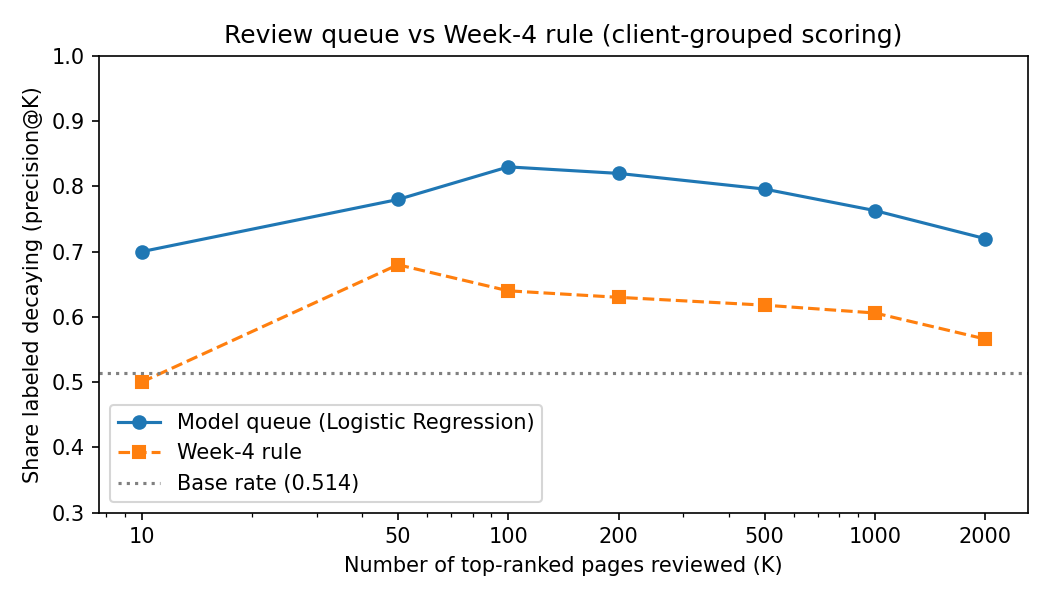

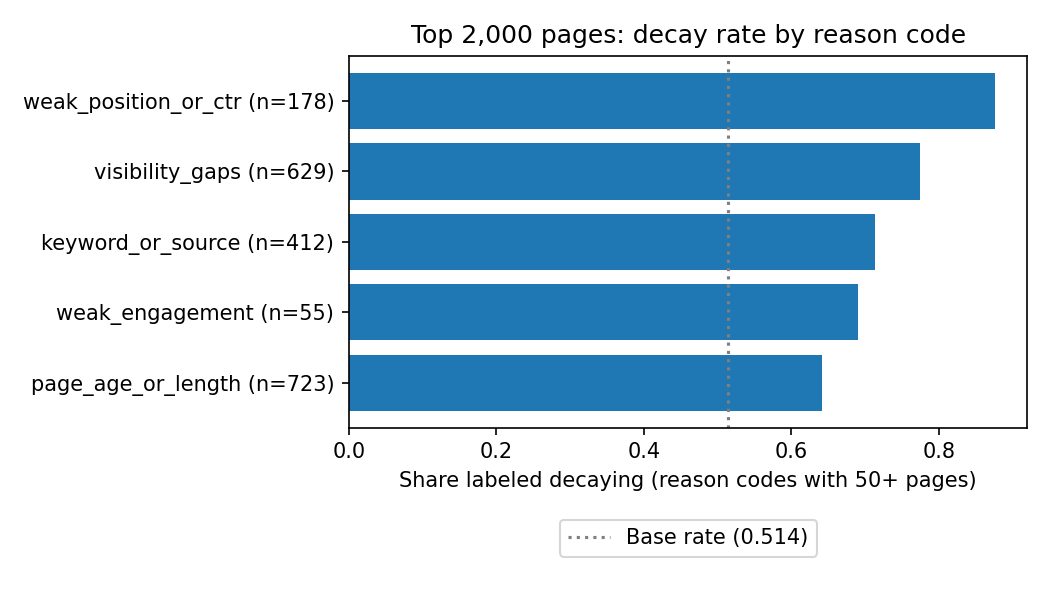

In [18]:
from IPython.display import Image, display
display(Image("work/figures/queue_precision_by_k.png"))
display(Image("work/figures/decay_rate_by_reason_code.png"))

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.